# Workshop #3 — Silver data-quality findings
Team 7 — Landslide Monitoring and Risk (Colombia). Reads every Silver Parquet file with **pandas** (one folder per
topic) and measures the issues that justify the governance KPIs of the Gold layer.

In [1]:
import json, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SILVER = ROOT / "datalake_silver"
GOLD = ROOT / "datalake_gold"
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

In [2]:
def load(topic):
    files = sorted((SILVER / topic).glob("*.parquet"))
    return pd.concat([pd.read_parquet(f) for f in files], ignore_index=True), len(files)

data = {t: load(t) for t in ["rainfall", "rainfall_historical", "landslides", "lhasa_hazard"]}
pd.DataFrame([{"topic": t, "files": n, "rows": len(df), "columns": df.shape[1]} for t, (df, n) in data.items()])

,topic,files,rows,columns
0,rainfall,6,10800,16
1,rainfall_historical,1,36530,14
2,landslides,1,109,46
3,lhasa_hazard,1,10,13


## 1. Null rates per field (non-zero only)

In [3]:
rows = []
for t, (df, _) in data.items():
    for c in df.columns:
        s = df[c]
        if s.dtype == object:
            nulls = s.isna() | s.astype(str).str.strip().eq("")
        else:
            nulls = s.isna()
        if nulls.any():
            rows.append({"topic": t, "field": c, "null_rate_%": round(100 * nulls.mean(), 2), "nulls": int(nulls.sum())})
nulls = pd.DataFrame(rows).sort_values("null_rate_%", ascending=False)
nulls

,topic,field,null_rate_%,nulls
1,landslides,event_time,100.00,109
6,landslides,storm_name,100.00,109
8,landslides,notes,98.17,107
7,landslides,photo_link,87.16,95
5,landslides,injury_count,74.31,81
11,landslides,country_name,7.34,8
9,landslides,event_import_source,7.34,8
10,landslides,event_import_id,7.34,8
12,landslides,country_code,7.34,8
13,landslides,admin_division_population,7.34,8


## 2. Duplicates: the same station-hour appears in several forecast polls
Each Open-Meteo poll repeats the previous 2 days, so the natural key (station, hour) is repeated across files, and the
values of the repeated hours are revised between polls.

In [4]:
rain = data["rainfall"][0]
dup = rain.duplicated(["station_name", "timestamp"], keep=False)
print(f"rows: {len(rain):,} | distinct station-hours: {rain[['station_name','timestamp']].drop_duplicates().shape[0]:,} | "
      f"rows whose key is repeated: {dup.mean():.1%}")
rev = rain[dup].groupby(["station_name", "timestamp"]).precipitation_mm.agg(["min", "max", "count"])
rev["revised"] = rev["max"] != rev["min"]
print(f"repeated station-hours whose precipitation changed between polls: {rev.revised.mean():.1%} "
      f"(largest change {(rev['max'] - rev['min']).max():.1f} mm)")

rows: 10,800 | distinct station-hours: 1,200 | rows whose key is repeated: 100.0%
repeated station-hours whose precipitation changed between polls: 36.5% (largest change 6.5 mm)


## 3. Outlier flags and quality flags

In [5]:
flags = []
for t, cols in {"rainfall": ["precip_outlier_iqr", "precip_outlier_zscore", "soil_moisture_imputed"],
                "landslides": ["fatality_outlier_iqr", "fatality_outlier_zscore", "country_missing", "fatality_missing", "is_time_unknown"],
                "rainfall_historical": ["precip_24h_missing"], "lhasa_hazard": ["has_high_hazard"]}.items():
    df = data[t][0]
    for c in cols:
        flags.append({"topic": t, "flag": c, "rate_%": round(100 * df[c].astype(float).mean(), 2)})
pd.DataFrame(flags)

,topic,flag,rate_%
0,rainfall,precip_outlier_iqr,3.89
1,rainfall,precip_outlier_zscore,1.25
2,rainfall,soil_moisture_imputed,0.00
3,landslides,fatality_outlier_iqr,6.42
4,landslides,fatality_outlier_zscore,0.92
5,landslides,country_missing,7.34
6,landslides,fatality_missing,4.59
7,landslides,is_time_unknown,64.22
8,rainfall_historical,precip_24h_missing,0.00
9,lhasa_hazard,has_high_hazard,0.00


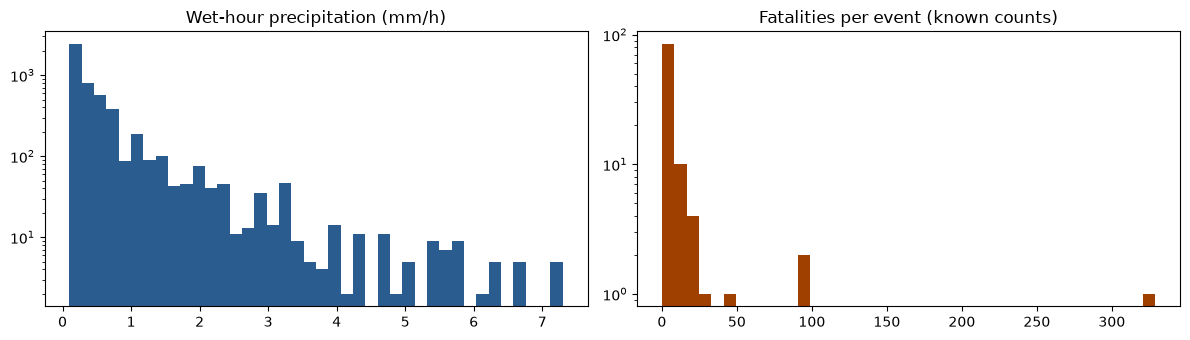

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
wet = rain[rain.precipitation_mm > 0]
ax[0].hist(wet.precipitation_mm, bins=40, color="#2b5c8f"); ax[0].set_title("Wet-hour precipitation (mm/h)"); ax[0].set_yscale("log")
gl = data["landslides"][0]
ax[1].hist(gl.fatality_count.dropna(), bins=40, color="#a04000"); ax[1].set_title("Fatalities per event (known counts)"); ax[1].set_yscale("log")
plt.tight_layout(); plt.show()

## 4. ERA5 annual totals: an anomalous station-year

In [7]:
hist = data["rainfall_historical"][0]
annual = hist.groupby(["station_name", "year"], observed=True).precip_24h_mm.sum().unstack().round(0)
ratio = annual.div(annual.median(axis=1), axis=0)
print("station-years above 2x their station median:")
print(ratio.stack().loc[lambda s: s > 2].round(2).to_string())
annual

station-years above 2x their station median:
station_name  year
Manizales     2016    2.90
Pereira       2016    4.59


year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
station_name,,,,,,,,,,
Bogota,1112.0,1045.0,880.0,905.0,743.0,811.0,1005.0,764.0,856.0,1053.0
Bucaramanga,7179.0,3041.0,3836.0,3349.0,5076.0,4604.0,4837.0,3282.0,3636.0,4063.0
Cali,3285.0,3362.0,3700.0,3775.0,3652.0,3936.0,3735.0,3012.0,2406.0,2878.0
Ibague,1655.0,3764.0,3999.0,3375.0,2983.0,4118.0,5260.0,4982.0,5223.0,5178.0
Manizales,17122.0,4931.0,6225.0,5600.0,6314.0,6675.0,6491.0,5511.0,4394.0,5479.0
Medellin,2702.0,2078.0,2106.0,1922.0,2198.0,2258.0,2686.0,1983.0,2176.0,2194.0
Mocoa,2618.0,3449.0,4783.0,4682.0,2887.0,4332.0,3963.0,4516.0,4930.0,6736.0
Pasto,2314.0,3530.0,3374.0,3390.0,3230.0,4606.0,4487.0,3457.0,3535.0,4147.0
Pereira,14500.0,2612.0,2492.0,2296.0,2458.0,3078.0,3780.0,3240.0,3393.0,4111.0


## 5. Text: narrative length, tokens and language

       len_chars  token_count
count      109.0        109.0
mean       567.9         55.1
std        324.2         31.0
min         71.0          8.0
25%        270.0         26.0
50%        577.0         55.0
75%        843.0         79.0
max       1264.0        120.0

Top tokens in Silver (before the Workshop #3 noise-word refinement):
people        108
landslide     103
said           83
colombia       82
department     67
rains          61
mudslide       56
heavy          53
two            52
killed         51
least          43
santander      41


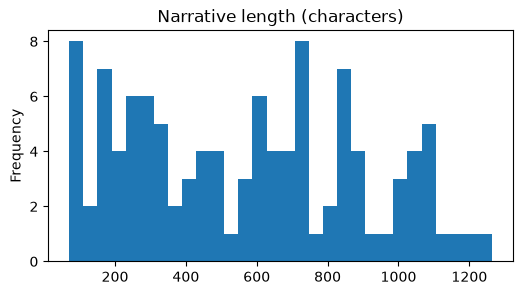

In [8]:
gl["len_chars"] = gl.raw_text_narrative.str.len()
print(gl[["len_chars", "token_count"]].describe().round(1))
tokens = pd.Series([t for lst in gl.tokens_nlp for t in lst])
print("\nTop tokens in Silver (before the Workshop #3 noise-word refinement):")
print(tokens.value_counts().head(12).to_string())
gl.len_chars.plot.hist(bins=30, figsize=(6, 3), title="Narrative length (characters)"); plt.show()

## 6. Time and coverage gaps

In [9]:
print(f"GLC events with unknown time (00:00): {gl.is_time_unknown.mean():.1%}")
polls = sorted(rain._bronze_source_file.unique())
print(f"forecast polls in Silver: {len(polls)}:", polls)
lh = data["lhasa_hazard"][0]
print("LHASA rasters in Silver:", lh.nominal_issue_time.dt.strftime('%Y-%m-%d').unique())

GLC events with unknown time (00:00): 64.2%
forecast polls in Silver: 9: ['openmeteo_forecast_20261121_064020.json', 'openmeteo_forecast_20261121_070009.json', 'openmeteo_forecast_20261121_071138.json', 'openmeteo_forecast_20261121_071715.json', 'openmeteo_forecast_20261121_150111.json', 'openmeteo_forecast_20261121_160004.json', 'openmeteo_forecast_20261121_162646.json', 'openmeteo_forecast_20261121_170005.json', 'openmeteo_forecast_20261121_172353.json']
LHASA rasters in Silver: <ArrowStringArray>
['2026-11-19']
Length: 1, dtype: str
